In [1]:
import numpy as np
import matplotlib.pyplot as plt
from inspectre import Inspectre
from matplotlib.colors import LogNorm

In [2]:
# build orbit
a = 0.9
p = 8.0
e = 0.3

r_min = p / (1.0 + e)
r_max = p / (1.0 - e)
r_mid = 0.5 * (r_min + r_max)

insp = Inspectre(spin=a, semilatus_rectum=p, eccentricity=e)
T_r = 2 * np.pi / insp.omega_r

In [3]:
# set field point
r, theta = r_mid, np.pi / 2 + 0.01

# set index ranges and time sampling
ms = list(range(21))
ns = np.arange(-20, 21)
N_t = 2048

## $(m,n)$-mode from `fft_nmodes_fast`

wrapper for `inspectre_fft_nmodes` using
- `inspectre_lib.c` on line 876
- `inspectre_mmode_projected` on line 811

### Setup
1. First grab radial period T_r = t(Λ_r), where Λ_r is the radial Mino period. The time grid is t_j = j·T_r/N for j = 0 … N−1. It is periodic so the endpoint T_r is not sampled.
2. Build one FFTW plan covering nq = 4·len(mlist) transforms of length N, done with `FFTW_BACKWARD`. There is one row per (m, quantity) pair, where "quantity" is {Phi, dr_Phi, dtheta_Phi, src}. The buffer is `buf[(i*4 + q)*N + j]`.

### Stage 1: projection over φ at each time sample t_j
1. Find λ_j from t_j by Newton iteration (`insp_lambda_newton`).

   - It starts from λ_{j−1} + (T_r/N)/(dt/dλ) and iterates λ ← λ − (t(λ) − t_j)/(dt/dλ), up to 20 times, until |Δλ| ≤ 4ε|λ|.
   - `info["newton_residual"]` is the largest |t(λ) − t_j|. `info["newton_maxit"]` counts samples that hit 20 iterations.

2. Place the particle at φ = 0 (`insp_set_particle(..., zeroPhi=1)`).

   - It computes ψ(λ), r_p, φ_p(λ) and u^r, sets the particle at (r_p, π/2, 0), and builds the coefficients in ctx. This is the expensive part of each slice (about 0.5 ms).
   - Putting the particle at φ = 0 lines the azimuth grid up with the particle (φ_0 = particle). The `nphi_rule` constants assume this alignment.

3. Choose N_φ.

   - C1 = (α₂₀Δr² + α₀₂Δθ²)/β.
   - If C1 ≤ 0, the slice is set to NaN and counted in `info["c1_zero"]`.
   - Otherwise N_φ = smallest power of two ≥ max(64, m_max + 16/√C1), capped at `nphi_max`. The factor of 16 was determined by an accuracy scan.

4. Sample.

   - At φ_k = 2πk/N_φ, the pointwise `effsource_equatorial_ctx_calc` gives four real rows: PhiS, ∂_r PhiS, ∂_θ PhiS and src.
   - N_φ evaluations at about 0.47 µs each.

5. Real FFT (r2c). The plan is cached per N_φ (`insp_rfft_get`) and does 4 transforms at once:

   F_q[m] = Σ_{k=0}^{N_φ−1} f_q(φ_k) e^{−2πi km/N_φ},  m = 0 … N_φ/2

   - The input is real, so the spectrum is Hermitian (F[−m] = F̄[m]). r2c returns only m ≥ 0, at half the cost and memory.
   - One transform gives every m in `mlist`, so the cost does not depend on how many `m` you ask for.
   - The largest `m` it can return is N_φ/2, so `m ≤ nphi_max/2` is checked.

6. Scale and rotate back to the true φ_p:

   f_{m,q}(t_j) = (2π/N_φ) · F_q[m] · e^{−imφ_p}

   - The factor 2π/N_φ is the trapezoid weight, so f_m ≈ ∫₀^{2π} f e^{−imφ} dφ. There is no 1/2π.
   - The e^{−imφ_p} factor undoes the φ = 0 placement. A field with the particle at φ_p is g(φ − φ_p) and its m-mode is e^{−imφ_p} times the m-mode of g.
   - In the code this is `w·(fr·cm + fi·sm, fi·cm − fr·sm)` = w·(fr + i·fi)(cos mφ_p − i sin mφ_p).
   - `mmode_projected_fast` stops after this step.

7. Frequency shift (`frequencyShift*` with n = 0):

   b_j = f_{m,q}(t_j) · e^{+imΩ_φ t_j}

   - f_m carries e^{−imφ_p(t)}, and φ_p(t) = Ω_φt + (a part periodic in T_r).
   - The shift removes the secular drift, which makes b_j periodic in T_r. A uniform-t trapezoid sum then converges spectrally.

### Stage 2: complex FFT over t
8. Backward complex FFT, divided by N:

   A_{m,q}[k] = (1/N) Σ_j b_j e^{+2πi jk/N}

   Since 2πjk/N = kΩ_r t_j, this becomes

   A_{m,q}[k] = (1/N) Σ_j f_m(t_j) e^{i(mΩ_φ + kΩ_r)t_j} ≈ (1/T_r) ∫₀^{T_r} f_m(t) e^{i(mΩ_φ + nΩ_r)t} dt

   - The transform is complex, not r2c, because b_j is complex after the rotation and the shift. +n and −n are unrelated and both halves of the spectrum are needed.
   - The backward sign (+i) matches the e^{+inΩ_r t} convention.
   - Bins with k > N/2 hold n = k − N (Step 4 earlier).

9. Output. The result goes into a flat `out[2*idx + {0,1}]`. The Python side reshapes it to `(nm, 4, N)` complex.

In [4]:
# this computes the (m,n) modes in one go
A, info = insp.fft_nmodes_fast(ms, r, theta, N_t, "numerical")
print(A.shape)
print(info)

(21, 4, 2048)
{'nphi_max': 4096.0, 'capped': 0.0, 'c1_zero': 0.0, 'newton_residual': 5.684341886080802e-14, 'newton_maxit': 0.0}


In [5]:
def mode(A, ms, m, n, tp=3):
    # little helper function to get a given (m,n) mode from stacked output array
    # tp is the type index (phi, dr_phi, dth_phi, src)
    N_t = A.shape[2]
    if not abs(n) < N_t // 2:
        raise ValueError(f"|n| = {abs(n)} not below N_t/2 = {N_t // 2}")
    return A[ms.index(m), tp, n % N_t]

In [6]:
# src (2,2)-mode
mode(A, ms, 2, 2)

np.complex128(0.00010333350628989888+4.1768118461378775e-17j)

In [7]:
# the (m,n) values are stacked on the ouput
mn = A[:, :, ns % N_t]
src_mn = mn[:, 3]

In [8]:
# do the integral over half a period and look at relative error over max mode amp
A_half, _ = insp.fft_nmodes_fast(ms, r, theta, N_t // 2, "numerical")
half = A_half[:, :, ns % (N_t // 2)]
for q, name in enumerate(["PhiS", "dPhiS_dr", "dPhiS_dth", "src"]):
    print(name, np.abs(half[:, q] - mn[:, q]).max() / np.abs(mn[:, q]).max())

PhiS 7.061904115586756e-17
dPhiS_dr 2.2574139187093052e-13
dPhiS_dth 1.373221857263995e-13
src 1.4130628523440878e-12


In [9]:
def c1_now(insp, r, theta):
    # build the C1 term
    ctx = insp.es._ef._ctx
    # get delta_r and delta_th
    dr, dth = r - ctx.xp.r, theta - ctx.xp.theta
    # rho hat / beta
    return (ctx.alpha20 * dr * dr + ctx.alpha02 * dth * dth) / ctx.beta

# pick number of azimuthal points from max(64, m_max + constant / sqrt(C1))
# m_max fixes the frequency scale
# 1/sqrt(C1) is the width of the complex pole, so this gives 
# an azimuthal resolution requirement
def nphi_form_b(c1, c=16, m_max=20, floor=64):
    # choose N_phi power of two from distance to equator
    chosen_pow = max(floor, m_max + c / np.sqrt(c1))
    return 2 ** int(np.ceil(np.log2(chosen_pow)))

# this runs the code piecemeal
# per time:
# - find t
# - get lamda
# - find the required azimuthal resolution from C1
# - get the m-mode integrated using rfft
# construct the n-mode via ifft
m_arr = np.array(ms)
S = np.empty((len(ms), 4, N_t), complex)
nphi = np.empty(N_t, int)
for j in range(N_t):
    t = j / N_t * T_r
    lam = insp.lambda_from_t(t)
    a64, _, _ = insp.mmode_projected_fast(ms + [32], r, theta, lam, 64)
    n = nphi_form_b(c1_now(insp, r, theta))
    nphi[j] = n
    a = a64 if n == 64 else insp.mmode_projected_fast(ms + [n // 2], r, theta, lam, n)[0]
    S[:, :, j] = a[:len(ms)] * np.exp(1j * m_arr * insp.omega_phi * t)[:, None]
mn_rule = np.fft.ifft(S, axis=2)[:, :, ns % N_t]


In [10]:
# high resolution in time for checking
N_ref = 8 * N_t
A_ref, info_ref = insp.fft_nmodes_fast(ms, r, theta, N_ref, "numerical")
mn_high_nt = A_ref[:, :, ns % N_ref]

In [11]:
names = ["PhiS", "dPhiS_dr", "dPhiS_dth", "src"]

def plot_mode_error(B, R, title, floor=1e-17, target=1e-8):
    
    # grab the error relative to the max mode amplitude
    err = np.abs(B - R) / np.abs(R).max(axis=(0, 2))[None, :, None]
    
    # lognorm the colorbar
    norm = LogNorm(vmin=floor, vmax=target)
    extent = (ns[0] - 0.5, ns[-1] + 0.5, ms[0] - 0.5, ms[-1] + 0.5)
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True, constrained_layout=True)
    
    for q, ax in enumerate(axes):
        im = ax.imshow(np.maximum(err[:, q], floor), norm=norm, cmap="Blues", origin="lower",
                       aspect="auto", extent=extent, interpolation="nearest")
        ax.set_title(f"{names[q]}   E = {np.nanmax(err[:, q]):.1e}", fontsize=10)
        ax.set_xlabel("n")
        ax.set_xticks(range(-20, 21, 10))
        ax.set_yticks(range(0, 21, 5))
    axes[0].set_ylabel("m")
    fig.colorbar(im, ax=axes, extend="max", label="|B − R| / max |R|")
    fig.suptitle(title, fontsize=11)
    return fig, err


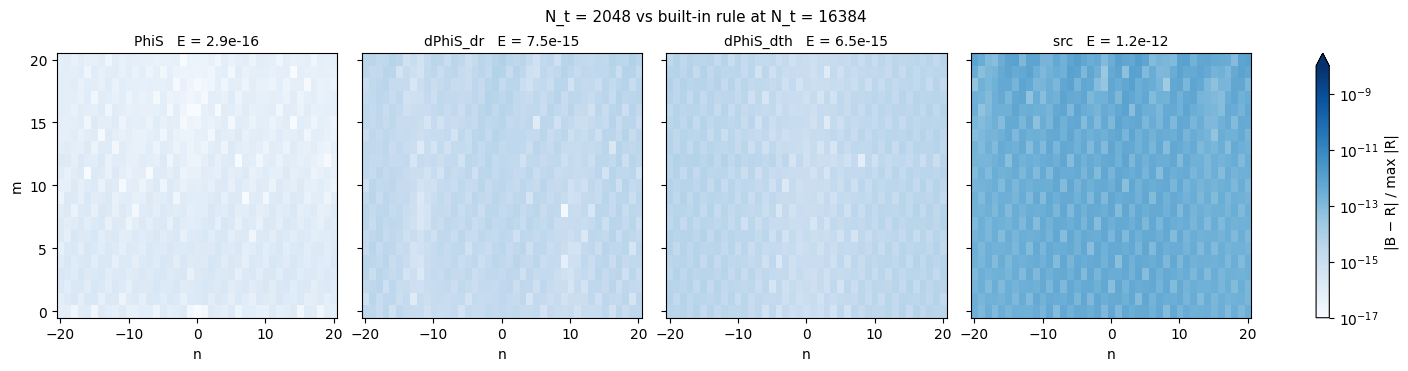

In [14]:
# plot the relative error
fig, err_tot = plot_mode_error(mn_rule, mn_high_nt, f"N_t = {N_t} vs built-in rule at N_t = {N_ref}")
plt.show()


## TD Reconstruction

### far from the equator

In [15]:
r, theta = r_mid, np.pi / 3.0
A, info = insp.fft_nmodes_fast(ms, r, theta, N_t, "numerical")

In [16]:
# shift the time bins to not get the exact time samples back from the FFT
t_rec = (np.arange(2 * N_t) + 0.5) * T_r / (2 * N_t)
direct = np.moveaxis(np.array([insp.mmode_projected_fast(ms, r, theta, insp.lambda_from_t(t))[0]
                               for t in t_rec]), 0, 2)
r_p = np.array([insp.r_from_lambda(insp.lambda_from_t(t)) for t in t_rec])
t_close = t_rec[np.argmin(np.abs(r_p - r))]

In [17]:
def reconstruct(A, ms, m, q, t, n_max, chunk=512):
    # compute A exp(-i(m Omega_phi + n Omega_r) t)
    N = A.shape[2]
    n = np.fft.fftfreq(N, 1.0 / N).astype(int)
    keep = np.abs(n) <= min(n_max, N // 2 - 1)
    w = m * insp.omega_phi + n[keep] * insp.omega_r
    return np.concatenate([np.exp(-1j * np.outer(tc, w)) @ A[ms.index(m), q, keep]
                           for tc in np.array_split(t, max(1, len(t) // chunk))])

def rel_err(rec, ref):
    return np.abs(rec - ref) / np.abs(ref).max()


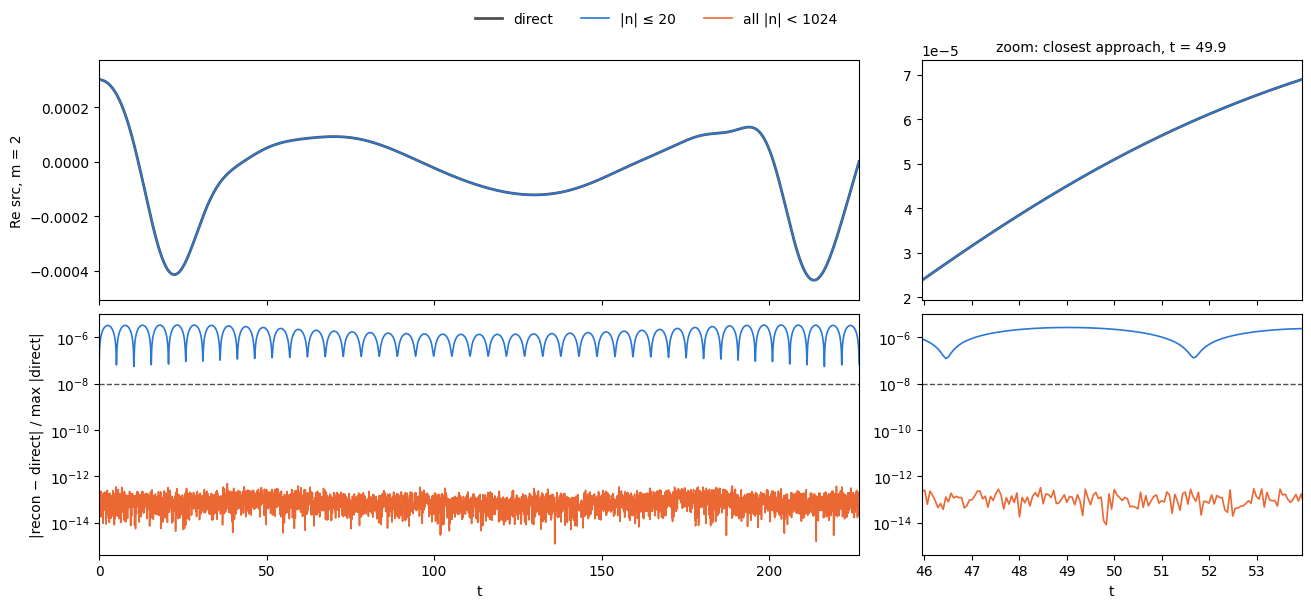

In [18]:
INK, BLUE, ORANGE = "#52514e", "#2a78d6", "#eb6834"
m_show, q_show, n_max = 2, 3, 20
d = direct[ms.index(m_show), q_show]
# rebuild truncated at |n|=20 or full n-modes
rec_trunc = reconstruct(A, ms, m_show, q_show, t_rec, n_max)
rec_full = reconstruct(A, ms, m_show, q_show, t_rec, N_t // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex="col", gridspec_kw={"width_ratios": (2, 1)},
                         constrained_layout=True)
for col, xlim in enumerate([(0, T_r), (t_close - 4, t_close + 4)]):
    win = (t_rec >= xlim[0]) & (t_rec <= xlim[1])
    lo, hi = d.real[win].min(), d.real[win].max()
    ax = axes[0, col]
    ax.plot(t_rec, d.real, color=INK, linewidth=2.0, label="direct")
    ax.plot(t_rec, rec_trunc.real, color=BLUE, linewidth=1.2, label=f"|n| ≤ {n_max}")
    ax.set_xlim(*xlim)
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax = axes[1, col]
    ax.semilogy(t_rec, np.maximum(rel_err(rec_trunc, d), 1e-17), color=BLUE, linewidth=1.2)
    ax.semilogy(t_rec, np.maximum(rel_err(rec_full, d), 1e-17), color=ORANGE, linewidth=1.2,
                label=f"all |n| < {N_t // 2}")
    ax.axhline(1e-8, color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel("t")
axes[0, 0].set_ylabel(f"Re {names[q_show]}, m = {m_show}")
axes[1, 0].set_ylabel("|recon − direct| / max |direct|")
axes[0, 1].set_title(f"zoom: closest approach, t = {t_close:.1f}", fontsize=10)
fig.legend(handles=[axes[0, 0].lines[0], axes[0, 0].lines[1], axes[1, 0].lines[1]],
           loc="outside upper center", ncol=3, frameon=False)
plt.show()


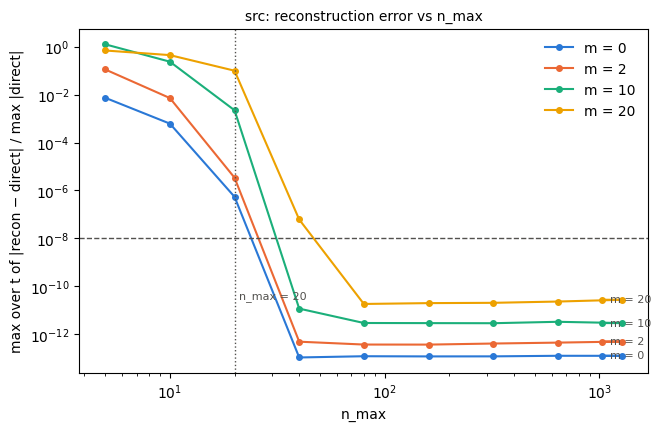

In [19]:
n_maxes = [5, 10, 20, 40, 80, 160, 320, 640, 1280, N_t // 2 - 1]
fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
for m, color in zip([0, 2, 10, 20], ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
    E = [rel_err(reconstruct(A, ms, m, q_show, t_rec, nm), direct[ms.index(m), q_show]).max() for nm in n_maxes]
    ax.loglog(n_maxes, E, "-o", color=color, markersize=4, label=f"m = {m}")
    ax.annotate(f"m = {m}", (n_maxes[-1], E[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.axhline(1e-8, color=INK, linestyle="--", linewidth=1)
ax.axvline(20, color=INK, linestyle=":", linewidth=1)
ax.text(21, 3e-11, "n_max = 20", fontsize=8, color=INK)
ax.set_xlabel("n_max")
ax.set_ylabel("max over t of |recon − direct| / max |direct|")
ax.set_title(f"{names[q_show]}: reconstruction error vs n_max", fontsize=10)
ax.legend(frameon=False)
plt.show()


### close to the equator

In [20]:
r, theta = r_mid, np.pi / 2 + 0.01
A, info = insp.fft_nmodes_fast(ms, r, theta, N_t, "numerical")

In [21]:
# shift the time bins to not get the exact time samples back from the FFT
t_rec = (np.arange(2 * N_t) + 0.5) * T_r / (2 * N_t)
direct = np.moveaxis(np.array([insp.mmode_projected_fast(ms, r, theta, insp.lambda_from_t(t))[0]
                               for t in t_rec]), 0, 2)
r_p = np.array([insp.r_from_lambda(insp.lambda_from_t(t)) for t in t_rec])
t_close = t_rec[np.argmin(np.abs(r_p - r))]

In [22]:
def reconstruct(A, ms, m, q, t, n_max, chunk=512):
    # compute A exp(-i(m Omega_phi + n Omega_r) t)
    N = A.shape[2]
    n = np.fft.fftfreq(N, 1.0 / N).astype(int)
    keep = np.abs(n) <= min(n_max, N // 2 - 1)
    w = m * insp.omega_phi + n[keep] * insp.omega_r
    return np.concatenate([np.exp(-1j * np.outer(tc, w)) @ A[ms.index(m), q, keep]
                           for tc in np.array_split(t, max(1, len(t) // chunk))])

def rel_err(rec, ref):
    return np.abs(rec - ref) / np.abs(ref).max()


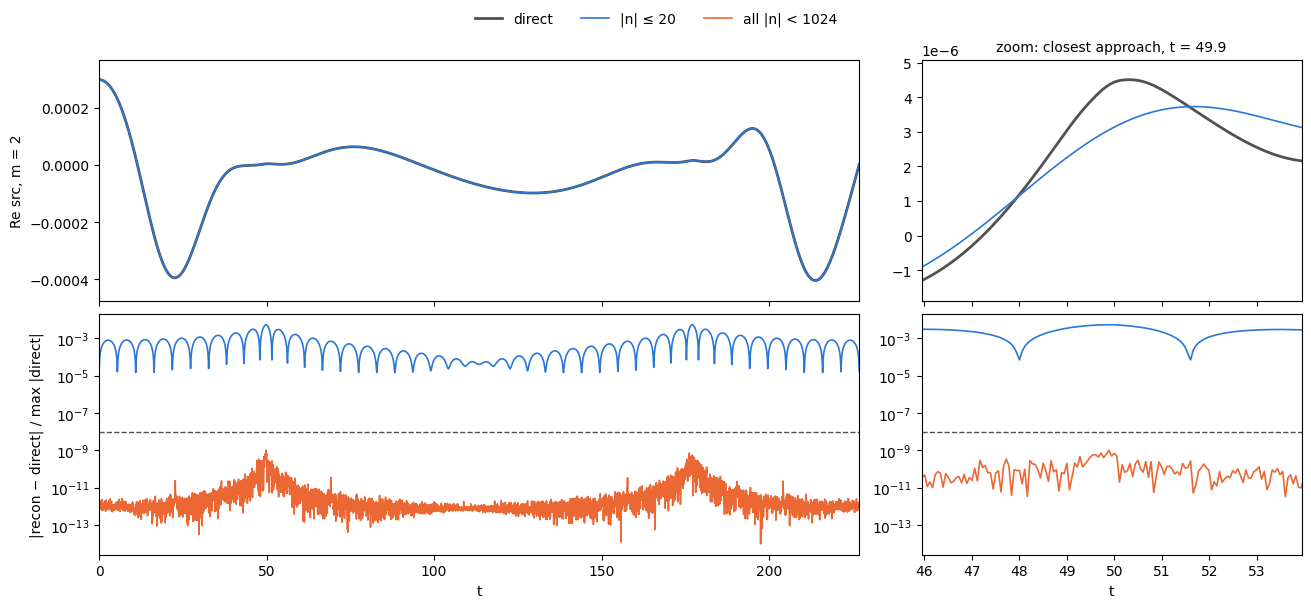

In [23]:
INK, BLUE, ORANGE = "#52514e", "#2a78d6", "#eb6834"
m_show, q_show, n_max = 2, 3, 20
d = direct[ms.index(m_show), q_show]
# rebuild truncated at |n|=20 or full n-modes
rec_trunc = reconstruct(A, ms, m_show, q_show, t_rec, n_max)
rec_full = reconstruct(A, ms, m_show, q_show, t_rec, N_t // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex="col", gridspec_kw={"width_ratios": (2, 1)},
                         constrained_layout=True)
for col, xlim in enumerate([(0, T_r), (t_close - 4, t_close + 4)]):
    win = (t_rec >= xlim[0]) & (t_rec <= xlim[1])
    lo, hi = d.real[win].min(), d.real[win].max()
    ax = axes[0, col]
    ax.plot(t_rec, d.real, color=INK, linewidth=2.0, label="direct")
    ax.plot(t_rec, rec_trunc.real, color=BLUE, linewidth=1.2, label=f"|n| ≤ {n_max}")
    ax.set_xlim(*xlim)
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax = axes[1, col]
    ax.semilogy(t_rec, np.maximum(rel_err(rec_trunc, d), 1e-17), color=BLUE, linewidth=1.2)
    ax.semilogy(t_rec, np.maximum(rel_err(rec_full, d), 1e-17), color=ORANGE, linewidth=1.2,
                label=f"all |n| < {N_t // 2}")
    ax.axhline(1e-8, color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel("t")
axes[0, 0].set_ylabel(f"Re {names[q_show]}, m = {m_show}")
axes[1, 0].set_ylabel("|recon − direct| / max |direct|")
axes[0, 1].set_title(f"zoom: closest approach, t = {t_close:.1f}", fontsize=10)
fig.legend(handles=[axes[0, 0].lines[0], axes[0, 0].lines[1], axes[1, 0].lines[1]],
           loc="outside upper center", ncol=3, frameon=False)
plt.show()


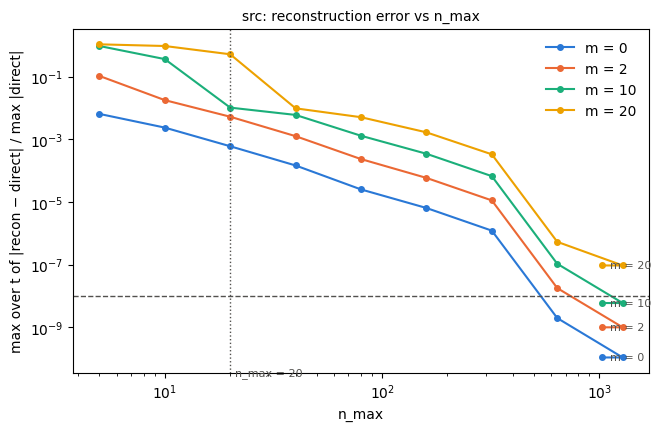

In [24]:
n_maxes = [5, 10, 20, 40, 80, 160, 320, 640, 1280, N_t // 2 - 1]
fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
for m, color in zip([0, 2, 10, 20], ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
    E = [rel_err(reconstruct(A, ms, m, q_show, t_rec, nm), direct[ms.index(m), q_show]).max() for nm in n_maxes]
    ax.loglog(n_maxes, E, "-o", color=color, markersize=4, label=f"m = {m}")
    ax.annotate(f"m = {m}", (n_maxes[-1], E[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.axhline(1e-8, color=INK, linestyle="--", linewidth=1)
ax.axvline(20, color=INK, linestyle=":", linewidth=1)
ax.text(21, 3e-11, "n_max = 20", fontsize=8, color=INK)
ax.set_xlabel("n_max")
ax.set_ylabel("max over t of |recon − direct| / max |direct|")
ax.set_title(f"{names[q_show]}: reconstruction error vs n_max", fontsize=10)
ax.legend(frameon=False)
plt.show()
